# Домашнее задание 1. Данные и baseline. 

### Андроник Диана, ПМИ 3 курс
---

## Описание данных

[Данные взяты отсюда](https://www.kaggle.com/datasets/harpartapsingh13/sleep-and-doomscrolling-habits-dataset)

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import math
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

df = pd.read_csv("sleep_doomscrolling_habits.csv")
print(df.shape)
df.head()


(1000, 30)


,respondent_id,age,bedtime_screen_time_minutes,total_daily_screen_time_hours,doomscroll_sessions_per_night,avg_doomscroll_session_minutes,sleep_hours_per_night,sleep_latency_minutes,number_of_night_wakeups,caffeine_intake_mg_per_day,...,occupation_status,country_region,primary_device_used_at_night,bedtime_routine_type,uses_night_mode,keeps_phone_in_bedroom,consumes_negative_news_content,uses_sleep_tracking_app,doomscroller,sleep_quality_category
0,D30000,22,13.0,1.85,2,5.4,8.1,19.0,2,155.0,...,Unemployed,Germany,Tablet,Meditation/Journaling,Yes,Yes,Yes,No,Yes,Good
1,D30001,18,90.0,3.61,3,29.6,7.0,31.0,3,82.0,...,Student,India,Smartphone,Meditation/Journaling,No,Yes,Yes,No,Yes,Poor
2,D30002,37,51.0,5.15,3,15.5,7.1,24.0,2,49.0,...,Student,India,Laptop,Reading,No,Yes,No,Yes,Yes,Fair
3,D30003,27,53.0,3.74,0,51.4,8.4,35.0,0,42.0,...,NaN,United States,Smartphone,No Fixed Routine,No,Yes,Yes,No,No,Fair
4,D30004,17,67.0,6.09,2,32.2,7.2,19.0,1,76.0,...,Employed Part-time,United States,Smartphone,Watching Videos,No,No,No,No,No,Fair


В датасете 1000 объектов и 29 признаков (без учёта id):


| Признак | Тип | Описание | Единицы измерения |
| --- | --- | --- | --- |
| `age` | числовой | Возраст | годы |
| `bedtime_screen_time_minutes` | числовой | Экранное время перед сном | минуты |
| `total_daily_screen_time_hours` | числовой | Экранное время за день | часы |
| `doomscroll_sessions_per_night` | числовой | Количество сессий doomscrolling-а в течение ночи | число (количество) |
| `avg_doomscroll_session_minutes` | числовой | Средняя продолжительность одной сессии doomscrolling-а | минуты |
| `sleep_hours_per_night` | числовой | Продолжительность сна за ночь | часы |
| `sleep_latency_minutes` | числовой | Время, необходимое для засыпания | минуты |
| `number_of_night_wakeups` | числовой | Количество пробуждений за ночь | число (количество) |
| `caffeine_intake_mg_per_day` | числовой | Количество потребляемого кофеина за день | мг/день |
| `anxiety_score` | числовой | Оценка уровня тревожности | баллы (1 - 10) |
| `stress_score` | числовой | Оценка уровня стресса | баллы (1 - 10)|
| `sleep_quality_score` | числовой | Числовая оценка качества сна | баллы (1 - 5)|
| `daytime_fatigue_score` | числовой | Оценка степени усталости в дневное время | баллы (1 - 10) |
| `number_of_news_apps_used` | числовой | Количество используемых новостных приложений | количество |
| `phone_checks_per_night` | числовой | Количество проверок телефона в течение ночи | количество |
| `exercise_minutes_per_day` | числовой | Продолжительность физических упражнений в течение дня | минуты/день |
| `days_since_last_digital_detox` | числовой | Количество дней с момента последнего цифрового детокса | дни |
| `weekly_sleep_debt_hours` | числовой | Недостаток сна, накопленный за неделю | часы |
| `gender` | категориальный | Пол | Male / Female |
| `occupation_status` | категориальный | Профессиональный стаус | Например, Student, Employed Part-time, Unemployed |
| `country_region` | категориальный | Страна проживания | название страны/региона |
| `primary_device_used_at_night` | категориальный | Основное электронное устройство, используемое ночью | например, Smartphone, Laptop, Tablet |
| `bedtime_routine_type` | категориальный | Основная активность перед сном | например, Reading, Meditation/Journaling, Watching Videos, No Fixed Routine |
| `uses_night_mode` | бинарный | Использует ли ночной режим на электронных устройствах | Yes / No |
| `keeps_phone_in_bedroom` | бинарный | Оставляет ли телефон в спальне во время сна | Yes / No |
| `consumes_negative_news_content` | бинарный | Потребляет ли негативный новостной контент | Yes / No |
| `uses_sleep_tracking_app` | бинарный | Использует ли приложение для отслеживания сна | Yes / No |
| `doomscroller` | бинарный | Имеет ли привычку doomscrolling-а | Yes / No |
| `sleep_quality_category` | **категориальный, target** | Категория качества сна | *Good / Fair / Poor* |


#### Задача:
Предсказать качество сна (классификация). Целевая переменная -- `sleep_quality_category`



---
## Обзор


In [4]:
overview = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "уникальных": df.nunique(),
    "пропусков": df.isna().sum(),
    "доля пропусков, %": (df.isna().mean() * 100).round(1),
})
display(overview)

,тип,уникальных,пропусков,"доля пропусков, %"
respondent_id,object,1000,0,0.0
age,int64,36,0,0.0
bedtime_screen_time_minutes,float64,136,0,0.0
total_daily_screen_time_hours,float64,496,0,0.0
doomscroll_sessions_per_night,int64,11,0,0.0
avg_doomscroll_session_minutes,float64,397,0,0.0
sleep_hours_per_night,float64,46,0,0.0
sleep_latency_minutes,float64,73,0,0.0
number_of_night_wakeups,int64,7,0,0.0
caffeine_intake_mg_per_day,float64,288,50,5.0


---
##  Одномерный анализ

#### Числовые признаки

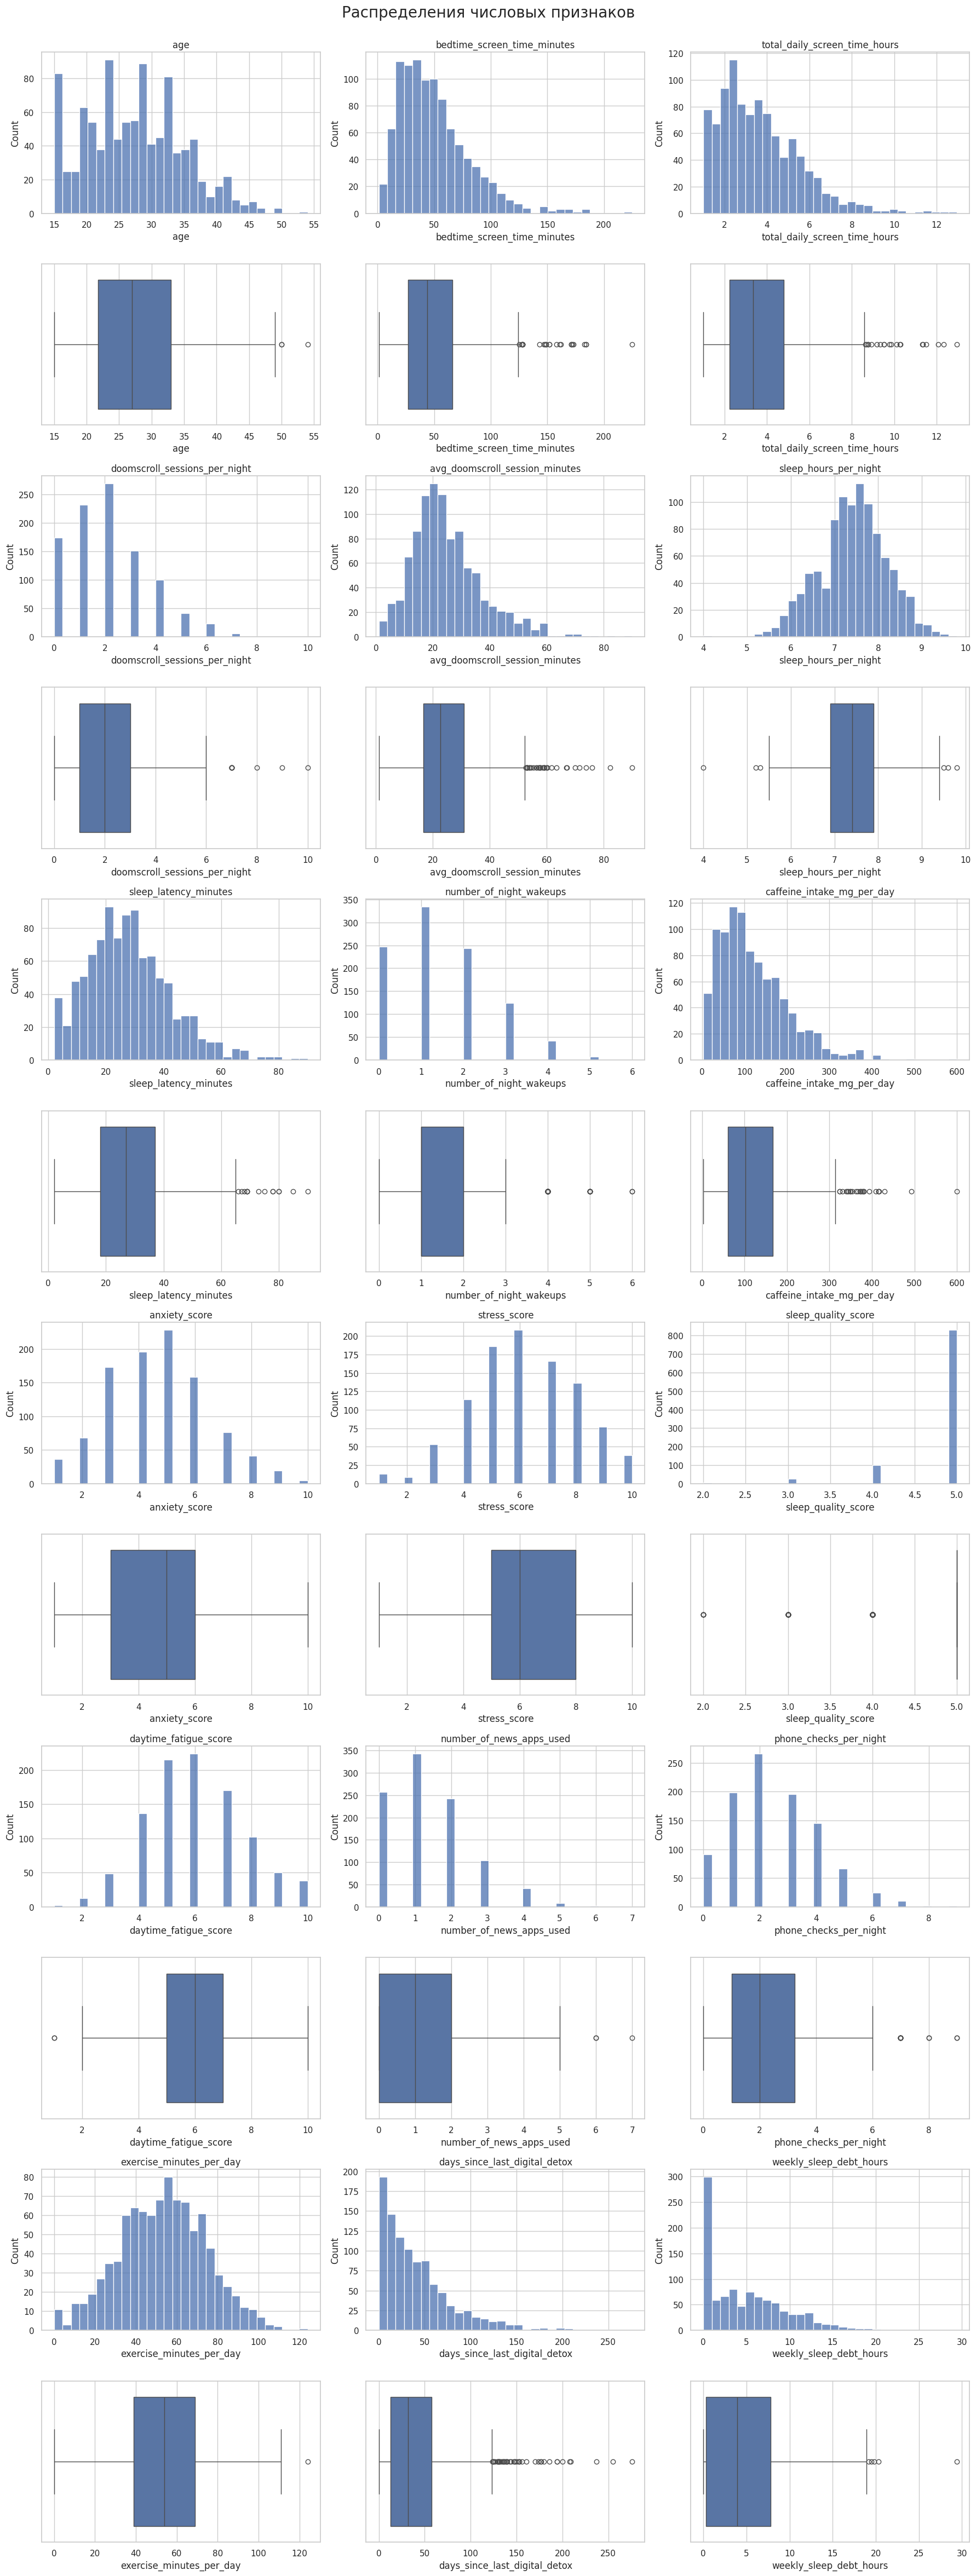

In [5]:
num_features = ["age", "bedtime_screen_time_minutes", "total_daily_screen_time_hours", "doomscroll_sessions_per_night", 
                "avg_doomscroll_session_minutes", "sleep_hours_per_night", "sleep_latency_minutes", "number_of_night_wakeups",
                "caffeine_intake_mg_per_day", "anxiety_score", "stress_score", "sleep_quality_score", "daytime_fatigue_score",
                "number_of_news_apps_used", "phone_checks_per_night", "exercise_minutes_per_day", "days_since_last_digital_detox",
                "weekly_sleep_debt_hours"]

cols = 3
num_rows = math.ceil(len(num_features) / cols)

fig, axes = plt.subplots(num_rows * 2, cols, figsize=(18, num_rows * 8))

for i, col in enumerate(num_features):
    row = (i // cols) * 2
    col_idx = i % cols
    sns.histplot(data=df, x=col, bins=30, ax=axes[row, col_idx])
    axes[row, col_idx].set_title(col)

    sns.boxplot(data=df, x=col, ax=axes[row + 1, col_idx])


fig.suptitle(
    "Распределения числовых признаков",
    fontsize=20
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Что видно:

- `age` — распределение неоднородное, с несколькими выраженными пиками в диапазоне примерно 15–35 лет. После 35 лет наблюдений заметно меньше
- `exercise_minutes_per_day` - основная масса наблюдений приходится на значения 30-80 минут в день. Есть отдельные большие значения, но без выраженной скошенности
- `weekly_sleep_debt_hours` - сильная скошеность вправо. Большая концентрация около небольших значений, после чего идёт длинный хвост в сторону большего дефицита сна
- `sleep_latency_minutes` - скошенность вправо: основная масса засыпает за 10–40 минут, но есть длинный хвост редких больших значений (60–90)
- Большинство признаков, связанных с использованием устройств (`bedtime_screen_time_minutes`, `total_daily_screen_time_hours`, `avg_doomscroll_session_minutes`, `days_since_last_digital_detox`), имеют выраженную скошенность вправо: основная масса наблюдений сосредоточена на небольших значениях, при этом присутствует длинный хвост больших значений
- Дискретные признаки (`doomscroll_sessions_per_night`, `number_of_night_wakeups`, `number_of_news_apps_used`, `phone_checks_per_night`) имеют концентрацию на небольшом количестве значений, а большие значения встречаются редко
- `anxiety_score`, `stress_score`, `daytime_fatigue_score` — распределение без выраженной скошенности, крайние значения встречаются редко
- `sleep_hours_per_night` и `exercise_minutes_per_day` - распрделение близко к симметричному
- `sleep_quality_score` - распределение сильно неравномерное, подавляющее большинство наблюдений имеет значение 5 

#### Категориальные признаки

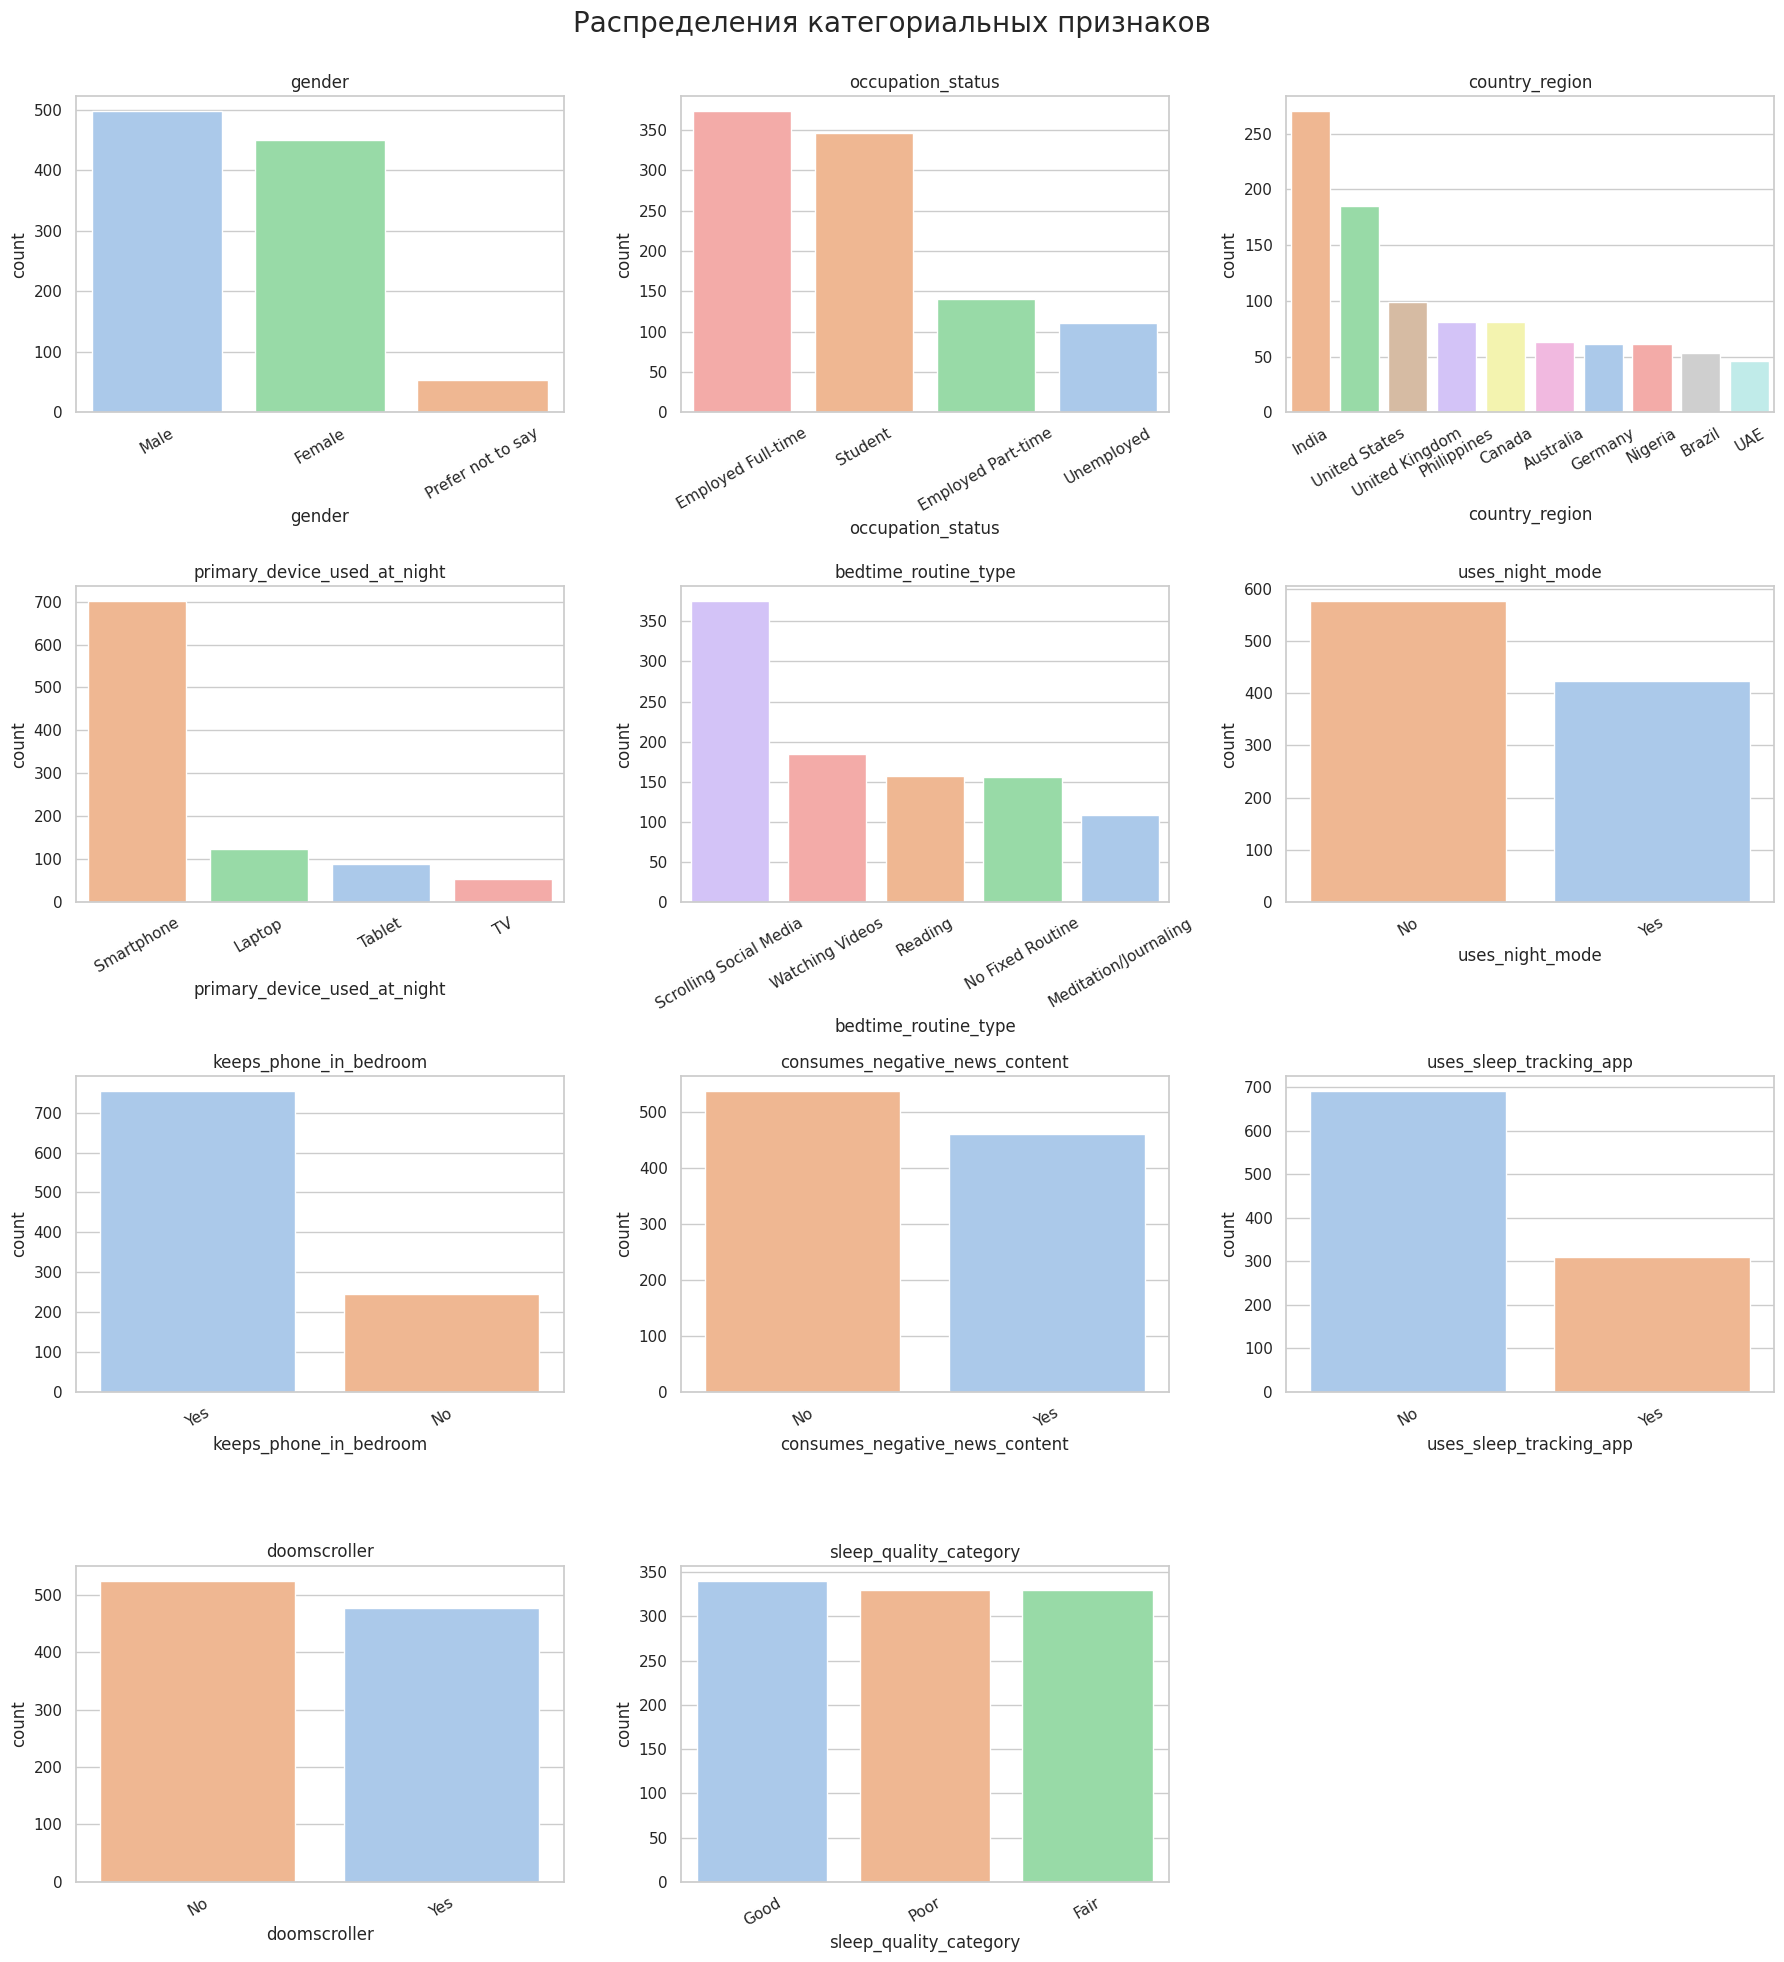

In [ ]:
cat_features = ["gender", "occupation_status", "country_region", "primary_device_used_at_night", 
                "bedtime_routine_type", "uses_night_mode", "keeps_phone_in_bedroom", "consumes_negative_news_content",
                "uses_sleep_tracking_app", "doomscroller", "sleep_quality_category"]

num_rows = math.ceil(len(cat_features) / cols)

fig, axes = plt.subplots(num_rows, cols, figsize=(18, num_rows * 5))


axes = axes.flatten()
for i, col in enumerate(cat_features):
    ax = axes[i]

    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue = col, order=order, ax=ax, palette="pastel", legend=False)

    ax.set_title(col)
    # ax.set_xlabel("")
    # ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=30)

for j in range(len(cat_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Распределения категориальных признаков",
    fontsize=20
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


Что видим:
- Многие признаки распределены достаточно равномерно
- Для `primary_device_used_at_night` явно преобладает Smartphone
- Для `bedtime_routine_type` чаще всего встречается Scrolling Social Media
- Для бинарных признаков `keeps_phone_in_bedroom` и `uses_sleep_tracking_app` характерен дисбаланс - в первом большинство держит телефон в спальне, во втором большинство не пользуется трекером сна — т.е. оба признака имеют явный перевес в одну сторону
- В `occupation_status`, `primary_device_used_at_night` и `bedtime_routine_type` присутствуют небольшие пропуски
- Целевая переменная `sleep_quality_category` распределена равномерно (!)


---
## Двумерный анализ

#### Категориальные признаки:
Рассмотрим связь категориальных признаков, относящихся непосредственно к использованию девайсов, с нашей целевой переменной:

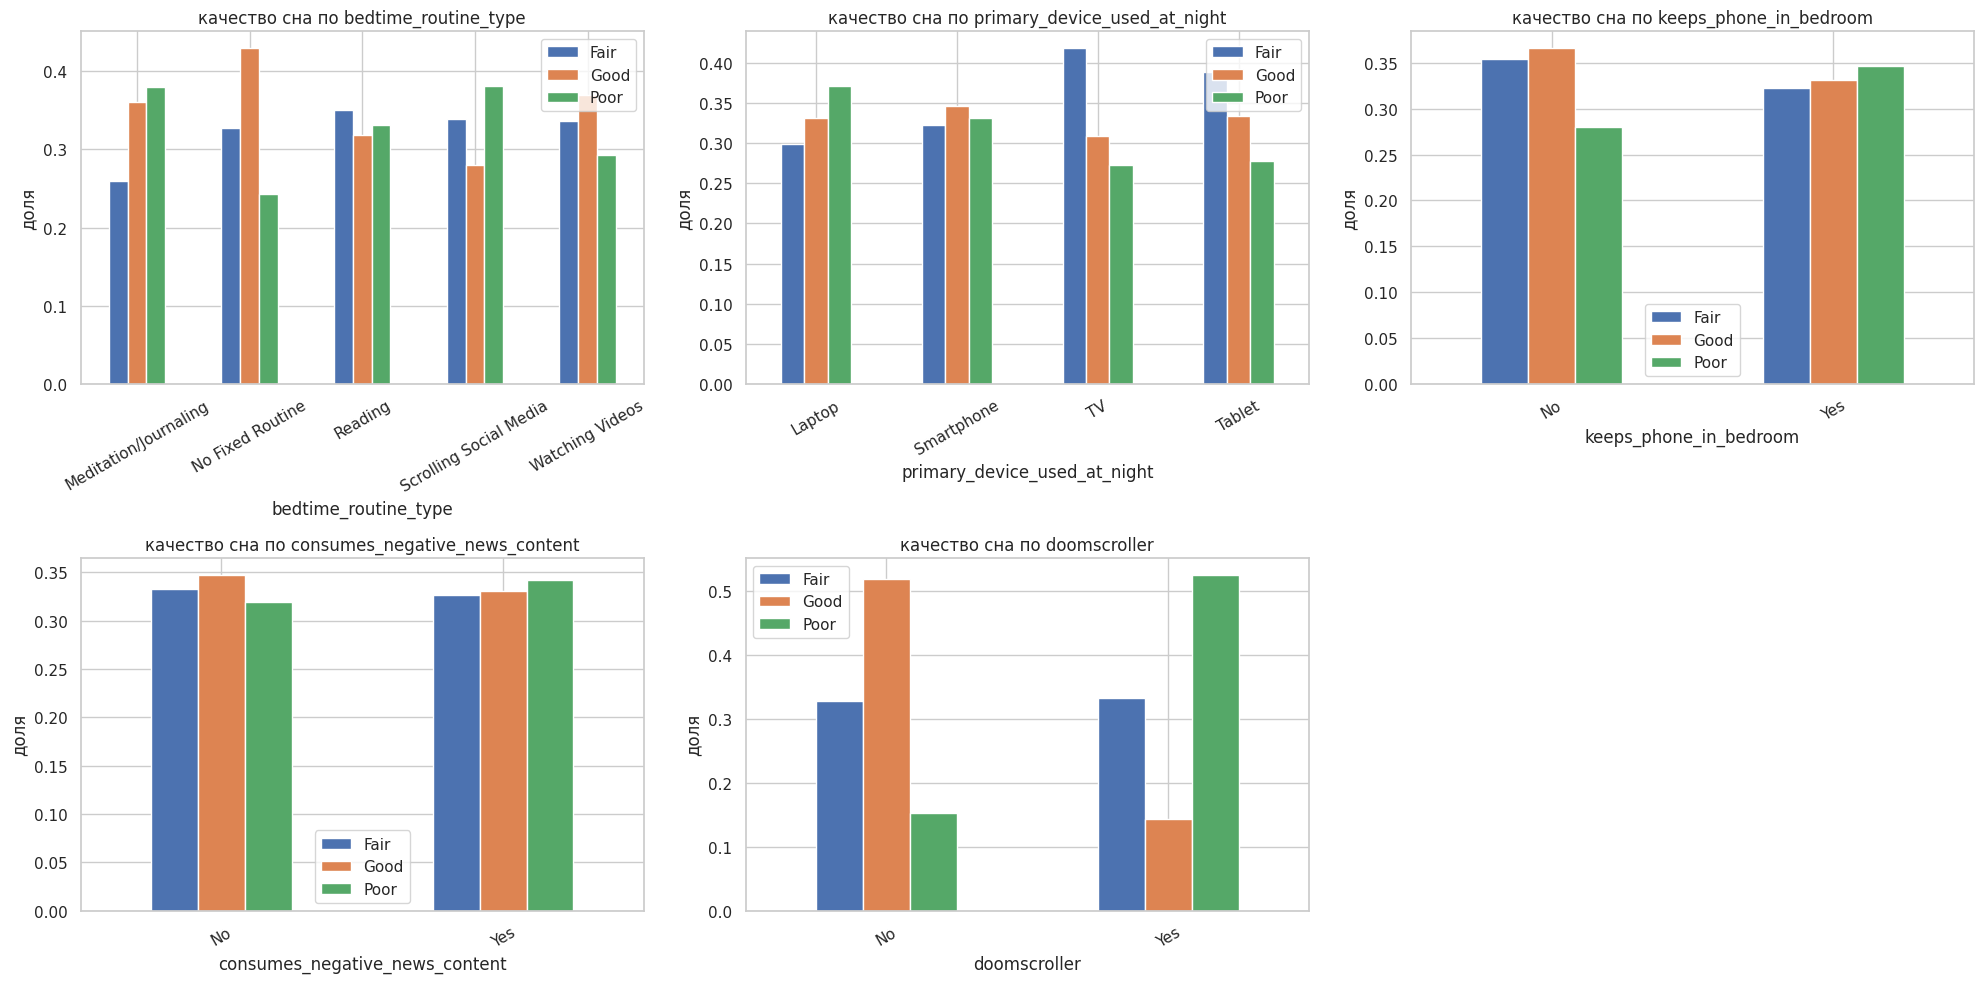

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

cat_tar_features = ["bedtime_routine_type", "primary_device_used_at_night", "keeps_phone_in_bedroom", 
                    "consumes_negative_news_content", "doomscroller"]

for ax, col in zip(axes, cat_tar_features):
    rates = pd.crosstab(df[col], df["sleep_quality_category"], normalize = "index")
    
    rates.plot(kind="bar", ax=ax)
    
    ax.set_title(f"качество сна по {col}")
    ax.set_ylabel("доля")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


Видим, что для большинства признаков распределение категорий качества сна существенно не различается

Наиболее выделяется признак `doomscroller`: среди тех, кто не имеет привычки скроллинга, чуть больше 50% имеют хорошее качество сна, и только порядка 15% - плохое. Среди же тех, кто имеет эту привычку, ситуация обратная: чуть больше половины имеют плохое качесто сна, и около 15% - хорошее. При этом доля категории **Fair** примерно одинаковая

#### Числовые признаки

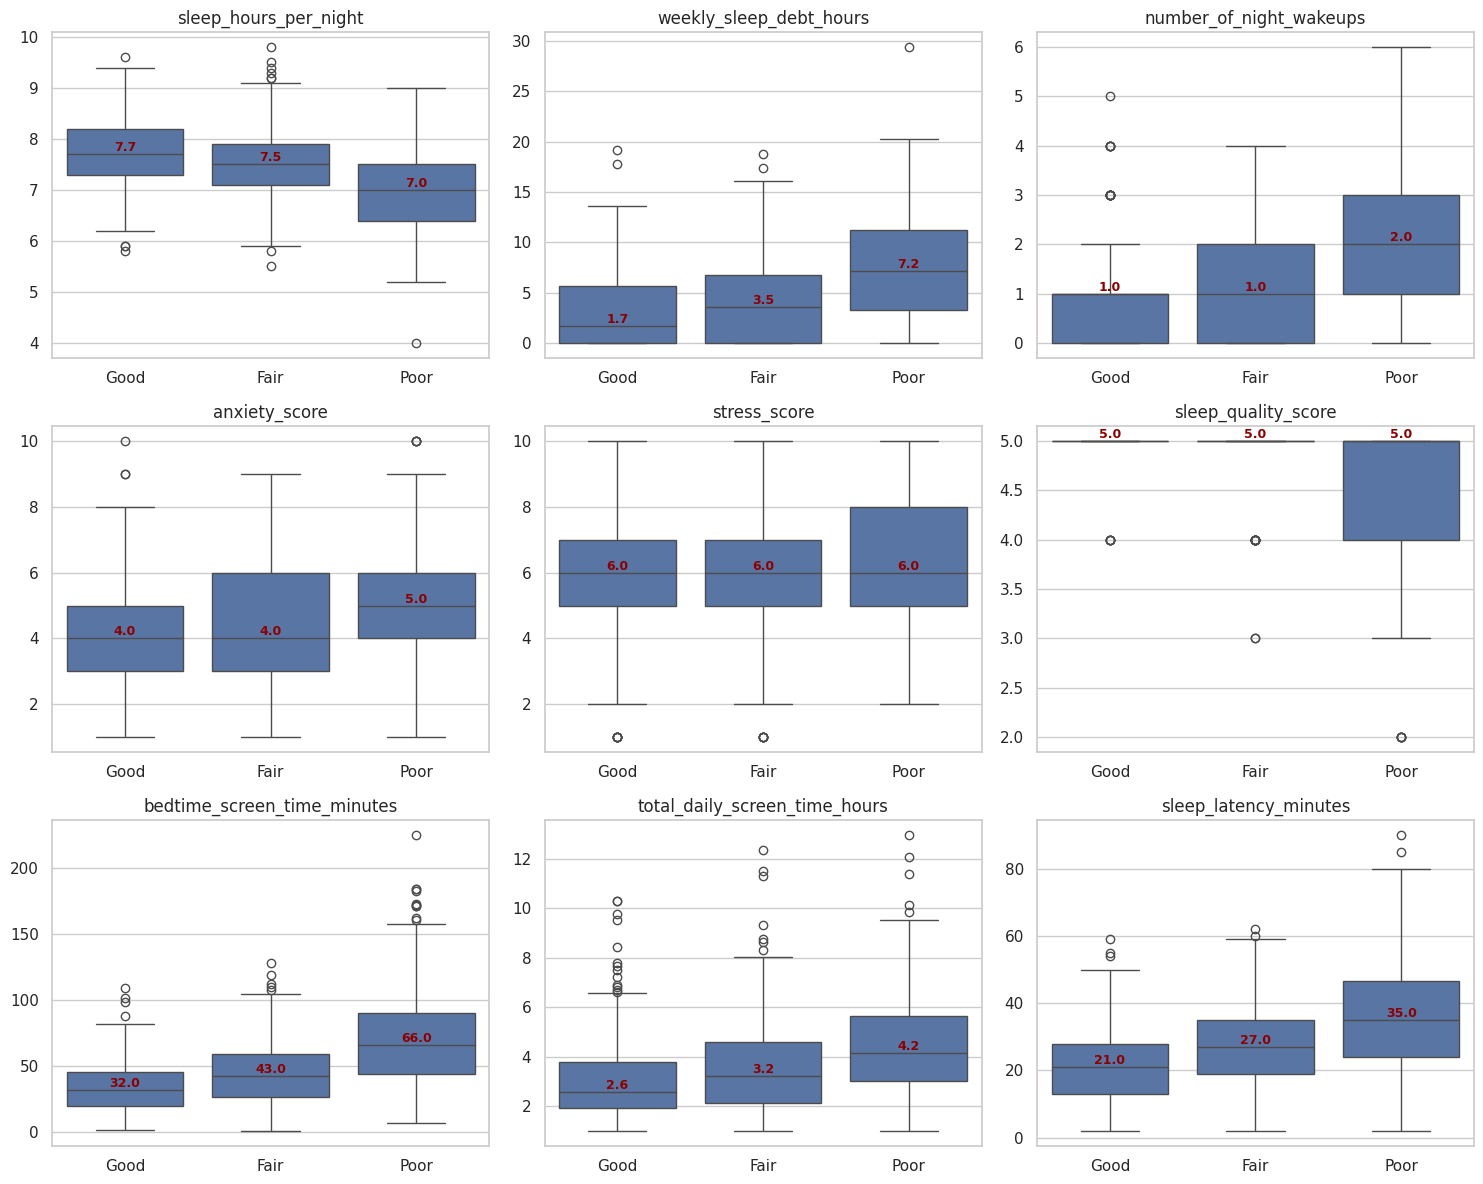

In [31]:
num_tar_features = ["sleep_hours_per_night", "weekly_sleep_debt_hours", "number_of_night_wakeups", "anxiety_score", "stress_score", 
                    "sleep_quality_score", "bedtime_screen_time_minutes", "total_daily_screen_time_hours", "sleep_latency_minutes"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, num_tar_features):
    sns.boxplot(data=df, x="sleep_quality_category", y=col, order=["Good", "Fair", "Poor"], ax=ax)

    medians = df.groupby("sleep_quality_category")[col].median().reindex(["Good", "Fair", "Poor"])
    for i, med in enumerate(medians):
        ax.text(i, med, f"{med:.1f}", ha="center", va="bottom", fontsize=9, color="darkred", fontweight="bold")
    
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

Что видим:
- Экранное время перед сном `bedtime_screen_time_minutes` заметно связано с качеством сна: медианное значение увеличивается с 32 минут для категории **Good** до 66 минут для **Poor**
- `sleep_latency_minutes` - при ухудшении качества сна увеличивается время, необходимое для засыпания: медиана составляет 21 минуту для **Good**, 27 минут для **Fair** и 35 минут для **Poor**
- `weekly_sleep_debt_hours` - тоже сильная связь: у людей с плохим качеством сна больше накопленного за неделю недостатка сна, медиана возрастает с 1,7 часа для **Good** до 7,2 часов для **Poor**    
- Для остальных признаков связь также есть, но не такая выраженная
- Также заметим, что `sleep_hours_per_night` связан с целевой переменной слабее, чем можно было ожидать: медиана постепенно снижается от 7,7 часа для **Good** до 7,0 часов для **Poor**, но распределения заметно перекрываются
- Отдельно стоит отметить признак `sleep_quality_score`: как мы уже видели, подавляющее большинство наблюдений имеют значение 5 (что довольно подозрительно с учётом равномерности распределения целевой переменной `sleep_quality_category`), при этом низкие значения встречаются в основном у категории `Poor`. Запомним этот признак, и вернёмся к нему позже

---
## Матрица корреляций для числовых признаков 

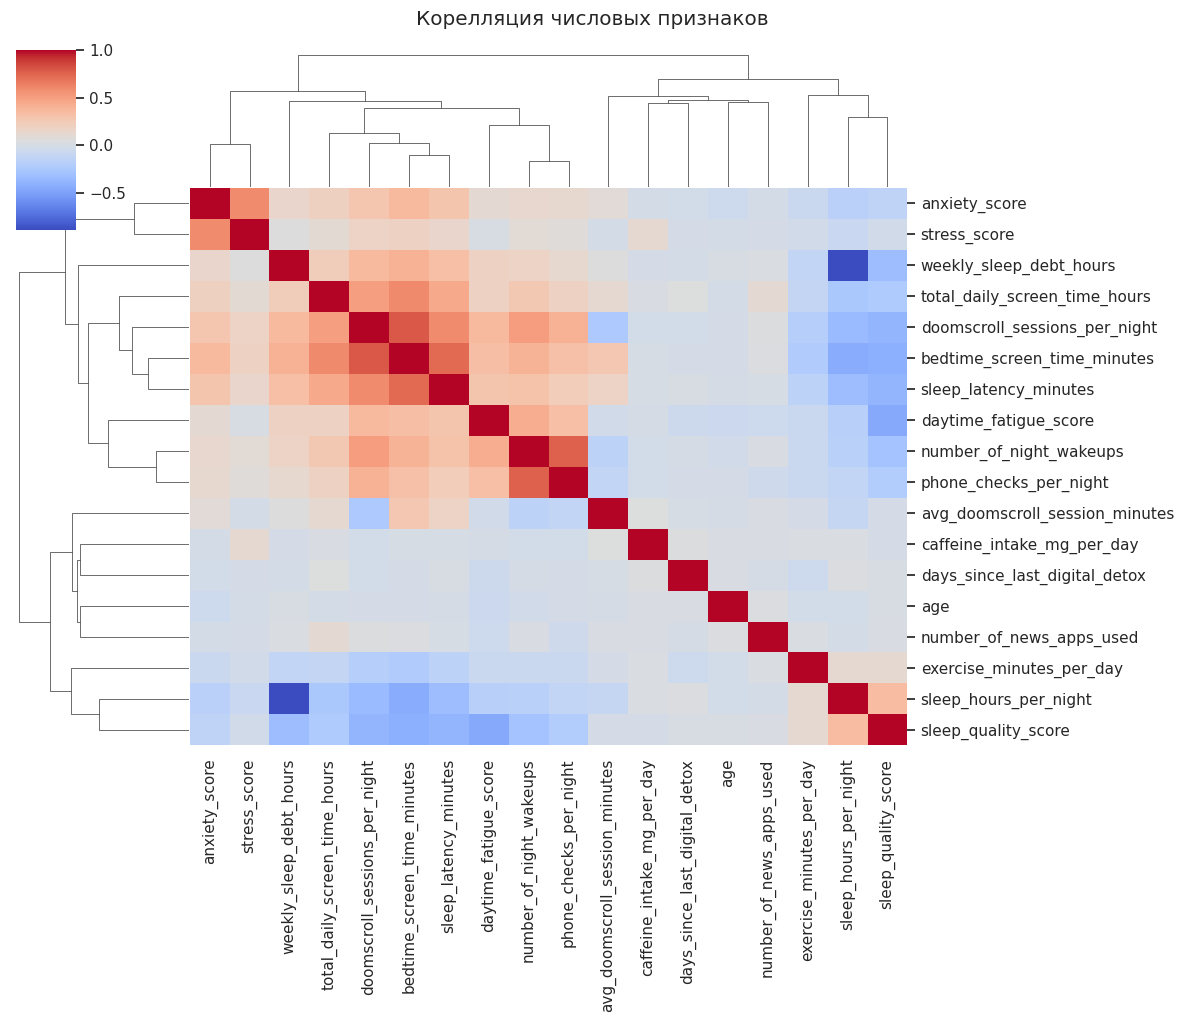

In [39]:
sns.clustermap(
    df[num_features].corr(),
    cmap="coolwarm",
    annot=False,
    figsize=(12, 10)
)

plt.suptitle("Корелляция числовых признаков", y=1.02)
plt.show()

Что видим:
- `sleep_hours_per_night` - `weekly_sleep_debt_hours`: сильная отрицательная корреляция. Чем больше человек спит за ночь, тем меньше у него накопленный дефицит сна, вполне логично)
- `bedtime_screen_time_minutes` - `doomscroll_sessions_per_night`: cильная положительная корреляция. Больше экранного времени перед сном связано с большим количеством doomscrolling-сессий, тоже логично
- `number_of_night_wakeups` - `phone_checks_per_night`: люди, которые чаще просыпаются ночью, чаще проверяют телефон
- `bedtime_screen_time_minutes` - `sleep_latency_minutes`: сильная положительная корелляция. Чем больше экранного времени перед сном, тем больше времени требуется для засыпания
- Явно подозрительных или нелогичных корреляций между признаками нет: наиболее сильные связи имеют понятную интерпретацию

---
## Пропуски

Общая информация:

In [49]:
missing_cols = df.columns[df.isna().any()]

for col in missing_cols:
    print(f"\n{'='*60}")
    print(col)
    print(f"Пропусков: {df[col].isna().sum()} ({df[col].isna().mean()*100:.1f}%)")
    
    if df[col].dtype == "object":
        print(df[col].value_counts(dropna=False))
    else:
        print(df[col].describe())


caffeine_intake_mg_per_day
Пропусков: 50 (5.0%)
count    950.000000
mean     120.752632
std       81.978478
min        3.000000
25%       61.000000
50%      102.000000
75%      166.000000
max      600.000000
Name: caffeine_intake_mg_per_day, dtype: float64

sleep_quality_score
Пропусков: 40 (4.0%)
count    960.000000
mean       4.828125
std        0.475292
min        2.000000
25%        5.000000
50%        5.000000
75%        5.000000
max        5.000000
Name: sleep_quality_score, dtype: float64

exercise_minutes_per_day
Пропусков: 50 (5.0%)
count    950.000000
mean      53.282105
std       21.158850
min        0.000000
25%       39.000000
50%       54.000000
75%       69.000000
max      124.000000
Name: exercise_minutes_per_day, dtype: float64

occupation_status
Пропусков: 30 (3.0%)
occupation_status
Employed Full-time    373
Student               346
Employed Part-time    140
Unemployed            111
NaN                    30
Name: count, dtype: int64

primary_device_used_at_night


Посмотрим на распределение `sleep_quality_category` среди наблюдений с пропуском и без:

In [51]:
for col in missing_cols:
    print(f"\n{'='*60}")
    print(col)
    
    missing_flag = df[col].isna()
    
    result = pd.crosstab(
        missing_flag,
        df["sleep_quality_category"],
        normalize="index"
    ).round(3)
    
    result.index = ["Значение есть", "Пропуск"]
    print(result)


caffeine_intake_mg_per_day
sleep_quality_category   Fair   Good   Poor
Значение есть           0.326  0.346  0.327
Пропуск                 0.400  0.220  0.380

sleep_quality_score
sleep_quality_category   Fair  Good   Poor
Значение есть           0.326  0.34  0.334
Пропуск                 0.425  0.35  0.225

exercise_minutes_per_day
sleep_quality_category   Fair   Good   Poor
Значение есть           0.331  0.341  0.328
Пропуск                 0.320  0.320  0.360

occupation_status
sleep_quality_category   Fair   Good   Poor
Значение есть           0.330  0.340  0.330
Пропуск                 0.333  0.333  0.333

primary_device_used_at_night
sleep_quality_category   Fair   Good   Poor
Значение есть           0.331  0.341  0.328
Пропуск                 0.300  0.300  0.400

bedtime_routine_type
sleep_quality_category  Fair   Good   Poor
Значение есть           0.33  0.336  0.335
Пропуск                 0.35  0.550  0.100


- Для `occupation_status` и `exercise_minutes_per_day` разницы практически нету. Для `exercise_minutes_per_day` будем использовать медиану 
- Для `caffeine_intake_mg_per_day` есть небольшая разница, но ввиду небольшого количества пропусков также будем использовать медиану
- Ещё можно отметить, что по матрице корреляции выше видно, что эти признаки не имеют сильных связей с другими числовыми признаками, поэтому использовать более сложные методы восстановления пропусков на основе других признаков нет основания
- Для `bedtime_routine_type` видно заметное отличие: среди наблюдений с пропуском 55% относятся к категории **Good** и только 10% к **Poor**. Однако количество таких наблюдений слишком мало, чтобы делать вывод связи между пропуском и качеством сна 
- Для категориальных признаков добавим отдельную категорию **Unknown**

(заполнять будем при разделении на train/test)

---
## Выбросы

Для категориальных признаков всё хорошо: ранее при анализе распределений категорий уже проверили уникальные значения и их частоты - явно некорректных значений нет

Посмотрим на выбросы в числовых признаках:

In [57]:
outlier_info = []

for col in num_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_info.append({
        "feature": col,
        "n_outliers": n_outliers,
        "min": df[col].min(),
        "max": df[col].max()
    })

outlier_info = pd.DataFrame(outlier_info)
outlier_info.sort_values("n_outliers", ascending=False)

,feature,n_outliers,min,max
11,sleep_quality_score,130,2.0,5.00
7,number_of_night_wakeups,52,0.0,6.00
16,days_since_last_digital_detox,46,0.0,276.00
4,avg_doomscroll_session_minutes,36,1.0,90.00
8,caffeine_intake_mg_per_day,25,3.0,600.00
1,bedtime_screen_time_minutes,24,1.0,225.00
2,total_daily_screen_time_hours,20,1.0,12.95
6,sleep_latency_minutes,15,2.0,90.00
14,phone_checks_per_night,14,0.0,9.00
3,doomscroll_sessions_per_night,9,0.0,10.00


Все минимумы и максимумумы являются реалистичными значениями, поэтому нет повода полагать, что это ошибки данных


---
## Конструирование признаков

In [59]:
def add_features(data):
    out = data.copy()

    # доля экранного времени, приходящегося на период перед сном (относительно общего за день)
    out["bedtime_screen_portion"] = (out["bedtime_screen_time_minutes"] / (out["total_daily_screen_time_hours"] * 60))

    # среднее время doomscrolling-а за ночь
    out["doomscroll_time_per_night"] = (out["doomscroll_sessions_per_night"] * out["avg_doomscroll_session_minutes"])

    # "недосып"
    out["short_sleep"] = (out["sleep_hours_per_night"] < 6).astype(int)

    return out


df_fe = add_features(df)
new_cols = [ "bedtime_screen_portion", "doomscroll_time_per_night", "short_sleep"]

display(df_fe[new_cols].head())

,bedtime_screen_portion,doomscroll_time_per_night,short_sleep
0,0.117117,10.8,0
1,0.415512,88.8,0
2,0.165049,46.5,0
3,0.236185,0.0,0
4,0.183361,64.4,0


Для проверки связи с целевой переменной для числовых признаков посмотрим средние значения и медиану по категориям:

In [68]:
order = ["Poor", "Fair", "Good"]

df_fe.groupby("sleep_quality_category")[["bedtime_screen_portion", "doomscroll_time_per_night"]].agg(["mean", "median"]).round(2).reindex(order)

bedtime_screen_portion         \
                                         mean median   
sleep_quality_category                                 
Poor                                     0.27   0.27   
Fair                                     0.24   0.24   
Good                                     0.22   0.22   

                       doomscroll_time_per_night         
                                            mean median  
sleep_quality_category                                   
Poor                                       68.47   65.5  
Fair                                       42.05   39.3  
Good                                       27.94   26.7

И распределение по категориальному:

In [ ]:
pd.crosstab(df_fe["short_sleep"], df_fe["sleep_quality_category"],normalize="index").reindex(columns=order).round(3)

sleep_quality_category,Poor,Fair,Good
short_sleep,,,
0,0.315,0.337,0.347
1,0.800,0.100,0.100


- Наиболее выраженная зависимость у `doomscroll_time_per_night`: среднее время `doomscrolling`-a составляет 68.47 минуты для категории **Poor**, 42.05 для **Fair** и 27.94 для **Good**
- Для `bedtime_screen_portion` также наблюдается постепенное увеличение значения от **Good** к **Poor**
- `short_sleep` показывает особенно заметное различие: среди людей, спящих менее 6 часов, у 80% качество сна относятся к категории **Poor**

---
##  Разбиение данных

In [87]:
from sklearn.model_selection import train_test_split

target = "sleep_quality_category"

X = df.drop(columns=[target, "respondent_id", "sleep_quality_score"])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

---
## Baseline


In [90]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score


baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

baseline_cv_scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="accuracy")
baseline.fit(X_train, y_train)
baseline_accuracy = baseline.score(X_test, y_test)

print(f"Baseline accuracy на кросс-валидации: {baseline_cv_scores.mean():.3f} ± {baseline_cv_scores.std():.3f}")
print(f"Baseline accuracy на тесте:           {baseline_accuracy:.3f}")

Baseline accuracy на кросс-валидации: 0.340 ± 0.003
Baseline accuracy на тесте:           0.340


---
## Пайплайн

In [103]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


model_num_features = [
    feature for feature in num_features
    if feature != "sleep_quality_score"
]

model_cat_features = [
    feature for feature in cat_features
    if feature != "sleep_quality_category"
]


preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), model_num_features),

    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), model_cat_features),
])

model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])


cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
model.fit(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print(f"Accuracy на кросс-валидации: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
print(f"Accuracy на тесте:           {test_accuracy:.3f}")

Accuracy на кросс-валидации: 0.576 ± 0.043
Accuracy на тесте:           0.625


Видим заметное улучшение по сравнению с Baseline

---
##  Анализ утечки

Возвращаемся к нашему `sleep_quality_score`. С одной стороны, этот признак связан с качеством сна и потенциально может (даже долже, я бы сказала) содержать информацию, использованную при формировании целевой переменной. С другой стороны, связь не является однозначной: значение 5 часто встречается у всех трёх категорий `sleep_quality_category`, хотя сама целевая переменная почти равномерно распределена между **Good**, **Fair** и **Poor**. При этом значения **sleep_quality_score** ниже 5 встречаются значительно реже.

Поэтому **sleep_quality_score** был исключён из признаков, используемых моделью.

По остальным признакам в ходе проведённого анализа явных признаков утечки обнаружено не было.

In [ ]:
# Напоминание распределения `sleep_quality_score`

pd.crosstab(
    df["sleep_quality_score"],
    df["sleep_quality_category"]
)

sleep_quality_category,Fair,Good,Poor
sleep_quality_score,,,
2.0,0,0,5
3.0,2,0,23
4.0,15,5,80
5.0,296,321,213


---
## Выводы

- В ходе анализа было установлено, что наиболее заметная связь с качеством сна наблюдается у признаков, связанных с doomscrolling-ом, продолжительностью сна и экранным временем
-  Были обнаружены пропуски в нескольких числовых и категориальных признаках, для которых выбраны простые стратегии заполнения внутри пайплайна
-  Также был выявлен подозрительный признак `sleep_quality_score`, поэтому он исключён из модели.

---
## Дополнительная часть

### (+1) Сравнить несколько стратегий заполнения пропусков и показать, какая даёт лучшее качество на кросс-валидации

In [100]:
imputation_strategies = ["median", "mean", "most_frequent"]
results = {}

for strategy in imputation_strategies:
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy=strategy)),
            ("scale", StandardScaler()),
        ]), model_num_features),

        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), model_cat_features),
    ])

    model_test = Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

    scores = cross_val_score(model_test, X_train, y_train, cv=5, scoring="accuracy")
    results[strategy] = (scores.mean(), scores.std())


for strategy, (mean, std) in results.items():
    print(f"{strategy}: {mean:.3f} ± {std:.3f}")

median: 0.576 ± 0.043
mean: 0.576 ± 0.043
most_frequent: 0.575 ± 0.040


Сравнение стратегий заполнения пропусков показало, что их влияние на качество модели практически отсутствует. Поэтому выбранная ранее стратегия заполнения медианой является вполне подходящей

---
### (+1) Добавить флаги пропусков как признаки и оценить, помогают ли они

In [102]:
preprocessor_missing_flags = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), model_num_features),

    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown", add_indicator=True)),
        ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), model_cat_features),
])

model_missing_flags = Pipeline([
    ("prep", preprocessor_missing_flags),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])


cv_scores_missing_flags = cross_val_score(model_missing_flags, X_train, y_train, cv=5, scoring="accuracy")
model_missing_flags.fit(X_train, y_train)
test_accuracy_missing_flags = model_missing_flags.score(X_test, y_test)

print(f"Accuracy на кросс-валидации: {cv_scores_missing_flags.mean():.3f} ± {cv_scores_missing_flags.std():.3f}")
print(f"Accuracy на тесте:           {test_accuracy_missing_flags:.3f}")

Accuracy на кросс-валидации: 0.571 ± 0.038
Accuracy на тесте:           0.630


Добавление индикаторов пропусков не улучшило качество модели на кросс-валидации: Accuracy снизилась с 0.576 до 0.571. Несмотря на небольшое повышение качества на тестовой выборке (с 0.625 до 0.630), этого недостаточно, чтобы считать что в данном случае флаги пропусков помогают